<a href="https://colab.research.google.com/github/vishwakumar1311/MiniGrad/blob/main/NeuralNetwork.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install torch

In [ ]:
import torch

tensor([1., 2., 3.])

In [ ]:
class Neuron:
  def __init__(self,values,children=(),op='',label='') -> None:
    self.values= values
    self.children= set(children)
    self.grad= 0
    self.op= op
    self.label= label
    self._backward = lambda: None
  def __repr__(self) -> str:
    return f'Neuron({self.label} {self.values})'
  def __mul__(self,other):
    other= other if isinstance(other,Neuron) else Neuron(other)
    out= Neuron(self.values*other.values,children=(self,other),op='*')
    def _backward():
      self.grad += other.values*out.grad
      other.grad += self.values*out.grad
    out._backward= _backward
    return out
  def __add__(self,other):
    other= other if isinstance(other,Neuron) else Neuron(other)
    out= Neuron(self.values+other.values,children=(self,other),op='+')
    def _backward():
      self.grad += out.grad
      other.grad += out.grad
    out._backward= _backward
    return out
  def __pow__(self,other):
    assert isinstance(other,(int,float)), 'only supporting int/float powers for now'
    out= Neuron(self.values**other,children=(self,),op=f'**{other}')
    def _backward():
      self.grad += other*(self.values**(other-1))*out.grad
    out._backward= _backward
    return out
  def __neg__(self):
      return self * -1
  def __sub__(self, other):
      return self + (-other)
  def __truediv__(self, other):
      return self * other**-1
  def __radd__(self, other):
      return self + other
  def __rmul__(self, other):
      return self * other
  def __rtruediv__(self, other):
      return other * self**-1
  def tanh(self):
    out= Neuron(np.tanh(self.values),children=(self,),op='tanh')
    def _backward():
      self.grad += (1-out.values**2)*out.grad
    out._backward= _backward
    return out
  def backward(self):
    topo=[]
    visited= set()
    def build_topo(v):
      if v not in visited:
        visited.add(v)
        for child in v.children:
          build_topo(child)
        topo.append(v)
    build_topo(self)
    self.grad=1.0
    for i in reversed(topo):
      i._backward()

In [ ]:
from graphviz import Digraph

def trace(root):
    nodes, edges = set(), set()
    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v.children:
                edges.add((child, v))
                build(child)
    build(root)
    return nodes, edges

def draw_dot(root):
    dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'}) # LR = Left to Right

    nodes, edges = trace(root)
    for n in nodes:
        uid = str(id(n))
        # for any value in the graph, create a rectangular ('record') node for it
        dot.node(name = uid, label = "{ %s | data %.4f | grad %4f }" % ( n.label, n.values,n.grad), shape='record')
        if n.op:
            # if this value is a result of some operation, create an op node and connect it to the value
            dot.node(name = uid + n.op, label = n.op)
            dot.edge(uid + n.op, uid)

    for n1, n2 in edges:
        # connect n1 to the op node of n2
        dot.edge(str(id(n1)), str(id(n2)) + n2.op)

    return dot

In [ ]:
x= Neuron(5)
y= Neuron(10)
print(x*y)
print(x)
z= x.tanh()
x.label='x'
y.label='y'
z.label='z'
print(z)

Neuron( 50)
Neuron( 5)
Neuron(z 0.9999092042625951)


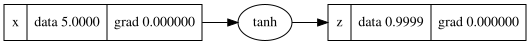

In [ ]:
draw_dot(z)

In [ ]:
import numpy as np

In [ ]:
class neuron:
  def __init__(self,n) -> None:
    self.w= [Neuron(np.random.randn(),label='w') for _ in range(n)]
    self.b= Neuron(np.random.randn(),label='b')
  def __call__(self,x):
    x_Neurons = [xi if isinstance(xi, Neuron) else Neuron(xi,label='value') for xi in x]
    act= sum((xi*wi for xi,wi in zip(x_Neurons,self.w)),self.b)
    out= act.tanh()
    return out
  def parameters(self):
    return self.w + [self.b]
class Layer:
  def __init__(self,no_inputs,no_neurons) -> None:
    self.neurons= [neuron(no_inputs) for _ in range(no_neurons)]
  def __call__(self,x):
    return [ n(x) for n in self.neurons]
  def parameters(self):
    return [p for neuron in self.neurons for p in neuron.parameters()]

class network:
  def __init__(self,no_inputs,no_layers):
    sz= [no_inputs]+no_layers
    self.network= [Layer(sz[i],sz[i+1]) for i in range(len(no_layers))]
  def __call__(self,x):
    for n in self.network:
      x= n(x)
    return x
  def parameters(self):
    return [p for layer in self.network for p in layer.parameters()]


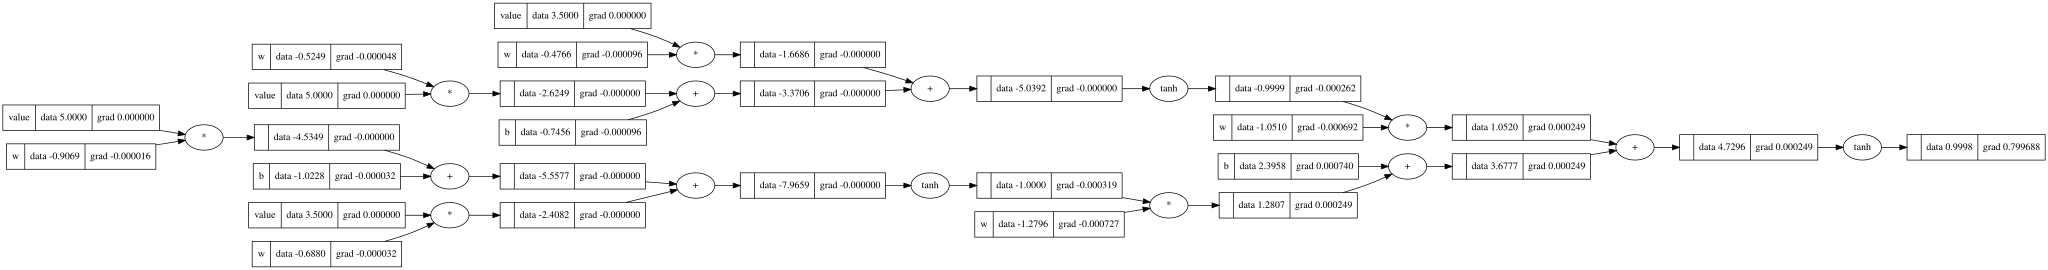

In [ ]:
draw_dot(out_pred[0][0])

In [ ]:
Q= network(2,[2,1])

In [ ]:
x_in= [[5,3.5],[0.5, 1.0]]
out_s= [0.6,0.4]

In [ ]:
for k in range(20):
  out_pred= [Q(xs) for xs in x_in]
  loss= sum((yout[0]-ygt)**2 for ygt,yout in zip(out_s,out_pred))

  for p in  Q.parameters():
    p.grad=0
  loss.backward()

  for p in Q.parameters():
    p.values += -1.5*p.grad

  print(k,loss.values)

0 0.09859669547561281
1 0.5149678918537852
2 0.5145141612890323
3 0.5139733160136457
4 0.5133182436815442
5 0.5125095285232031
6 0.5114877266232205
7 0.5101591107096443
8 0.5083675371862788
9 0.5058340859972352
10 0.5020129386469028
11 0.4956948257164948
12 0.48367814666293757
13 0.45481012254633646
14 0.34838739477856395
15 0.1718634734539386
16 0.519636749607504
17 0.5196344612264059
18 0.5196321439751295
19 0.5196297973051874


In [ ]:
print(out_pred)

[[Neuron( 0.9999967549486252)], [Neuron( 0.999991166589544)]]


In [ ]:
a=torch.tensor([[1.0,2.0,3.0],[4.0,5.0,6.0]])
b=torch.tensor([5.0,10.0,15.0])
c=torch.zeros(2,2)
a.size()

torch.Size([2, 3])